# Part 1: Discrete Local Search

In [128]:
from workload_data_loader import load_workload_instance

workload_28 = load_workload_instance("multi_resource_n28_m2.txt")
print(f"n = {workload_28[0]}")
print(f"m = {workload_28[1]}")
print(f"Utilities shape = {workload_28[2].shape}")
print(f"Demands shape = {workload_28[3].shape}")
print(f"Capacities shape = {workload_28[4].shape}")

n = 28
m = 2
Utilities shape = (28,)
Demands shape = (2, 28)
Capacities shape = (2,)


In [129]:
import numpy as np

def get_options(workload):
    return workload[0]

def get_resources(workload):
    return workload[1]

def get_utilities(workload):
    return workload[2]

def get_demands(workload):
    return workload[3]

def get_capacities(workload):
    return workload[4]

def evaluate(workload, solution):
    usage = np.dot(get_demands(workload), solution)
    utility = np.dot(get_utilities(workload), solution)
    valid_solution = not any([d > c for (d, c) in zip(usage, get_capacities(workload))])

    return valid_solution, utility if valid_solution else 0, utility, usage

print(evaluate(workload_28, np.zeros(28)))
print(evaluate(workload_28, np.ones(28)))

(True, np.float64(0.0), np.float64(0.0), array([0., 0.]))
(False, 0, np.float64(164045.0), array([1125.,  995.]))


In [130]:
def random_solution(workload):
    return np.random.randint(0, 2, get_options(workload))

def neighbour(solution):
    idx = np.random.randint(0, len(solution))

    new_solution = np.copy(solution)
    new_solution[idx] = 0 if new_solution[idx] == 1 else 1#

    return new_solution

demo_random_sol = random_solution(workload_28)
demo_neighbour = neighbour(demo_random_sol)
print(demo_random_sol)
print(demo_neighbour)
print()
print(np.abs(demo_random_sol - demo_neighbour))

[0 1 0 0 1 0 0 0 0 0 1 0 1 0 1 0 0 1 1 0 1 1 1 1 0 0 0 0]
[0 1 0 0 1 0 0 0 0 1 1 0 1 0 1 0 0 1 1 0 1 1 1 1 0 0 0 0]

[0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
def norm_usage(workload, usage):
    return np.linalg.norm(usage / get_capacities(workload))

# TODO implement multiple constraint avoidance mechanisms. compare average performance
def hill_climb(workload, n):
    trace = []
    best_sol = random_solution(workload)
    best_eval = evaluate(workload, best_sol)
    trace.append(best_eval[1])

    for _ in range(n):
        neig = neighbour(best_sol)
        neig_eval = evaluate(workload, neig)
        if neig_eval[1] > best_eval[1]:
            best_sol = neig
            best_eval = neig_eval

        if neig_eval[1] == best_eval[1]:
            if norm_usage(workload, neig_eval[3]) < norm_usage(workload, best_eval[3]):
                best_sol = neig
                best_eval = neig_eval

        trace.append(best_eval[1])

    return best_sol, best_eval, trace

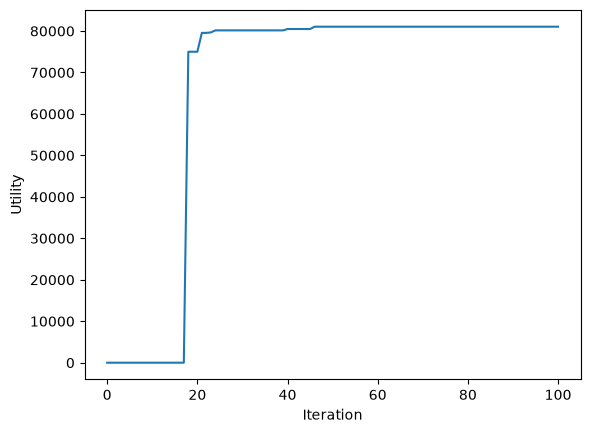

In [156]:
import matplotlib.pyplot as plt
%matplotlib inline


plt.plot(hill_climb(workload_28, 100)[2])
plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.show()

# Part 2: Advanced Metaheuristic Engineering

In [133]:
workload_90 = load_workload_instance("multi_resource_n90_m5.txt")
print(f"n = {workload_90[0]}")
print(f"m = {workload_90[1]}")
print(f"Utilities shape = {workload_90[2].shape}")
print(f"Demands shape = {workload_90[3].shape}")
print(f"Capacities shape = {workload_90[4].shape}")

n = 90
m = 5
Utilities shape = (90,)
Demands shape = (5, 90)
Capacities shape = (5,)


# Part 3: Empirical Study and Hypothesis Testing